# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import HiUCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Multilabel mask

Total number of patches: 12000


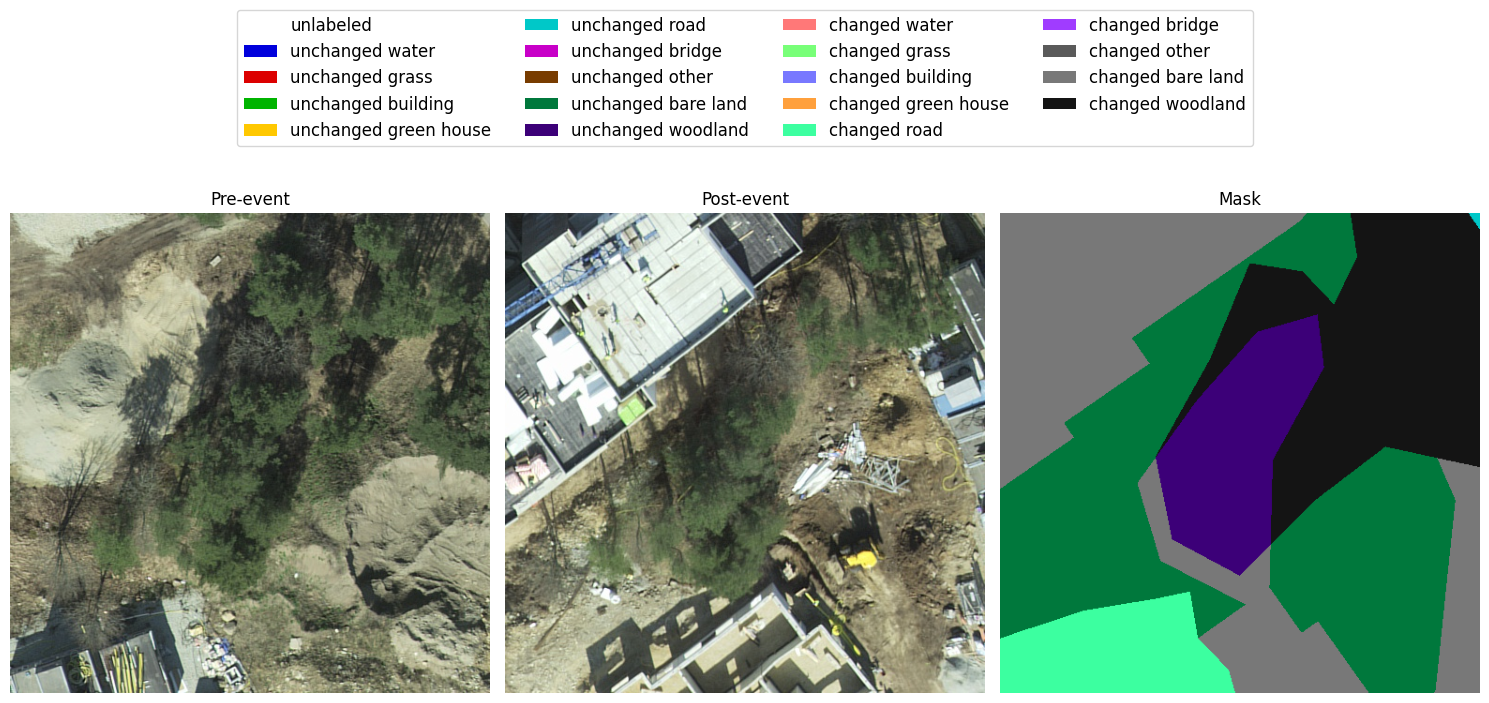

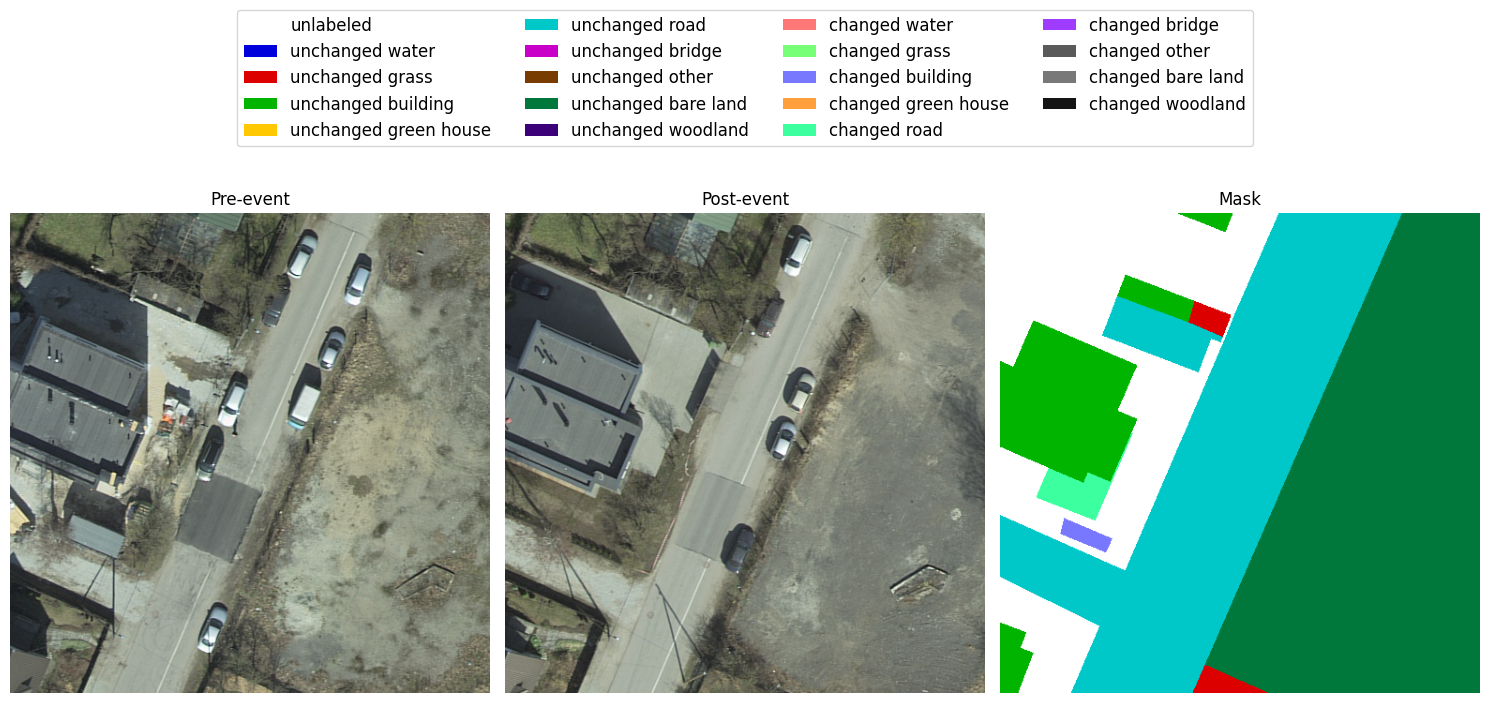

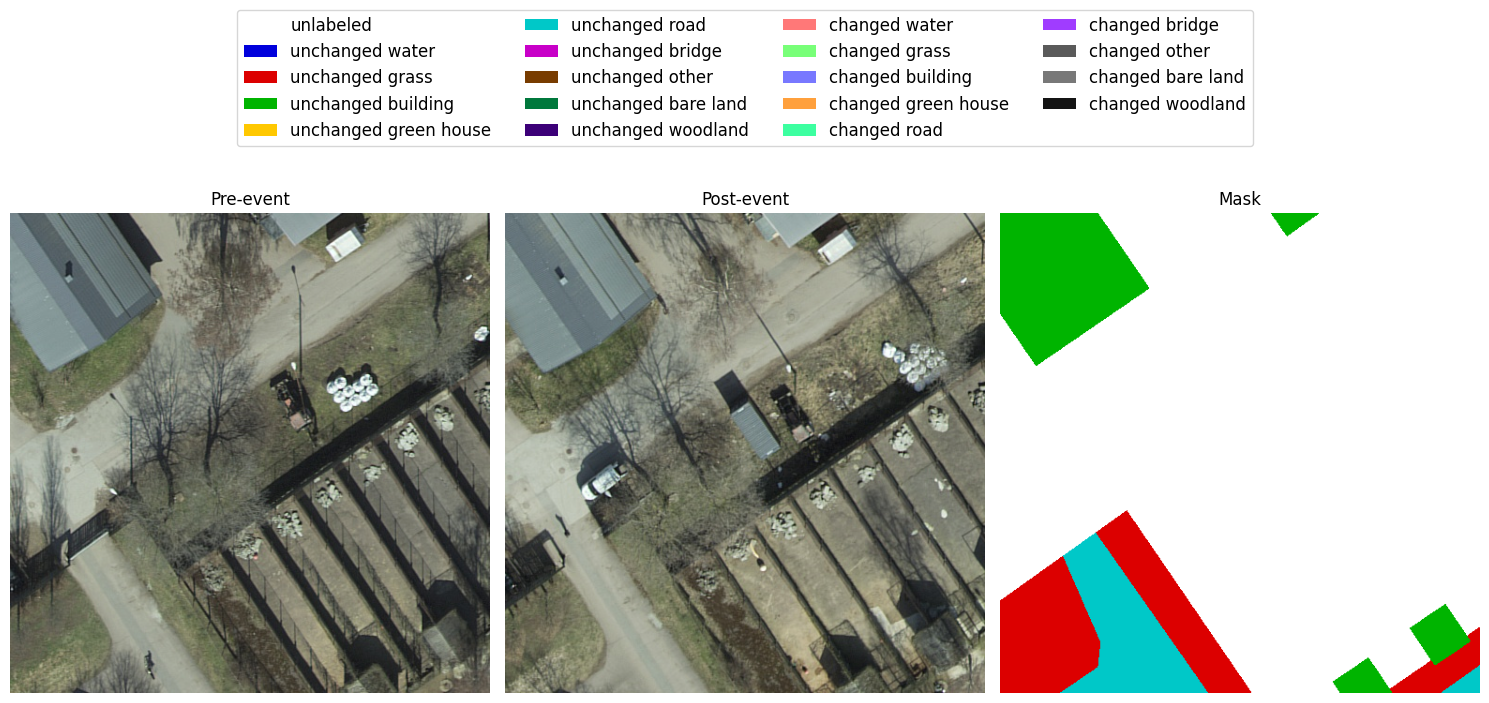

In [5]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/hi_ucd/train/",
    "task_type": "multilabel"
}
dataset = HiUCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(48);
dataset.show_image(29);
dataset.show_image(2000);

In [9]:
dataset.data_distribution_table()

,Number of pixels
unlabeled,752555465.0
unchanged water,32393853.0
unchanged grass,540263539.0
unchanged building,398546898.0
unchanged green house,1810987.0
unchanged road,673875191.0
unchanged bridge,1174556.0
unchanged other,1285099.0
unchanged bare land,236651185.0
unchanged woodland,471832920.0


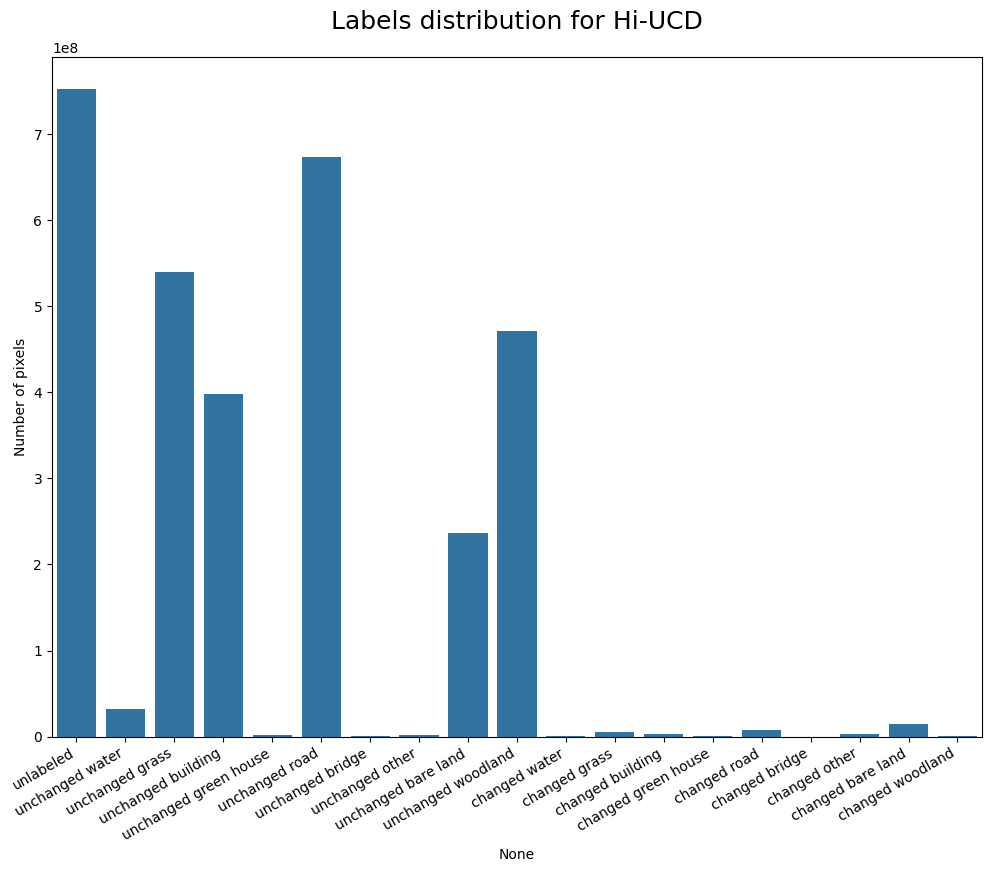

In [10]:
dataset.data_distribution_barchart();

Binary mask

Total number of patches: 12000


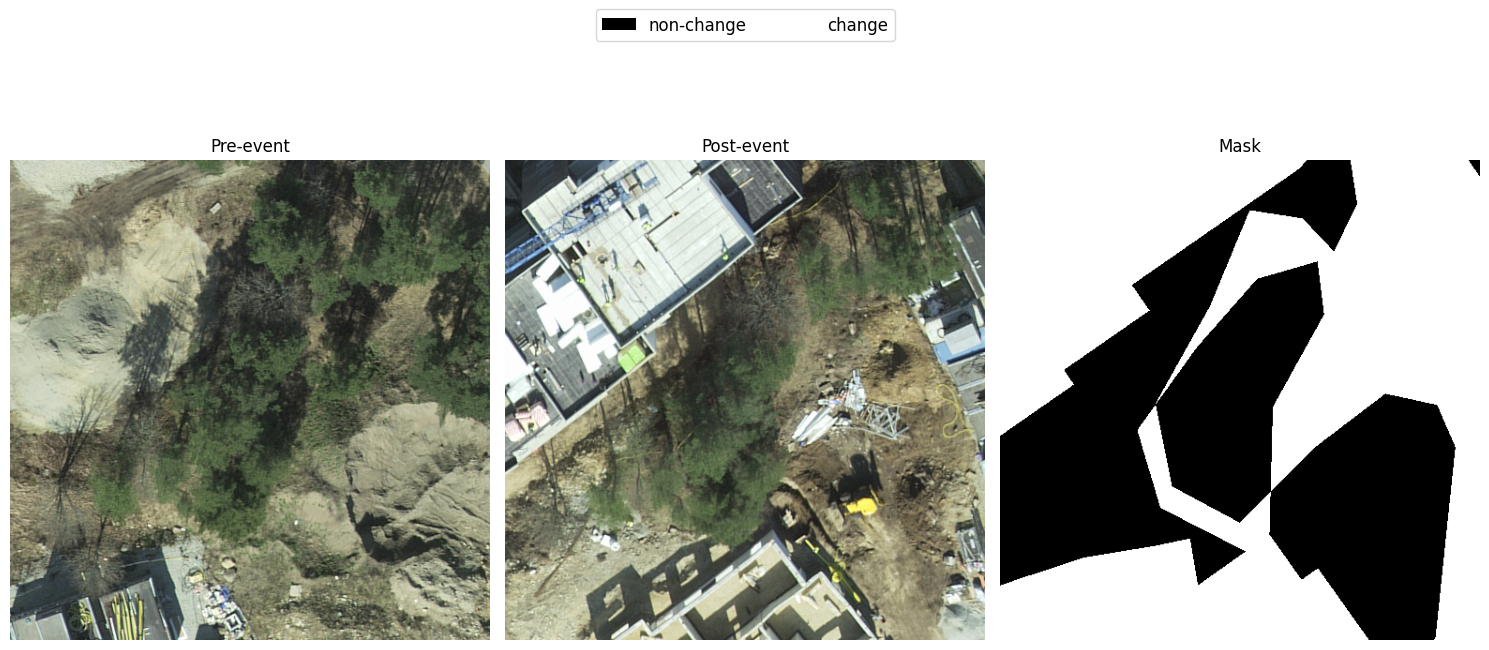

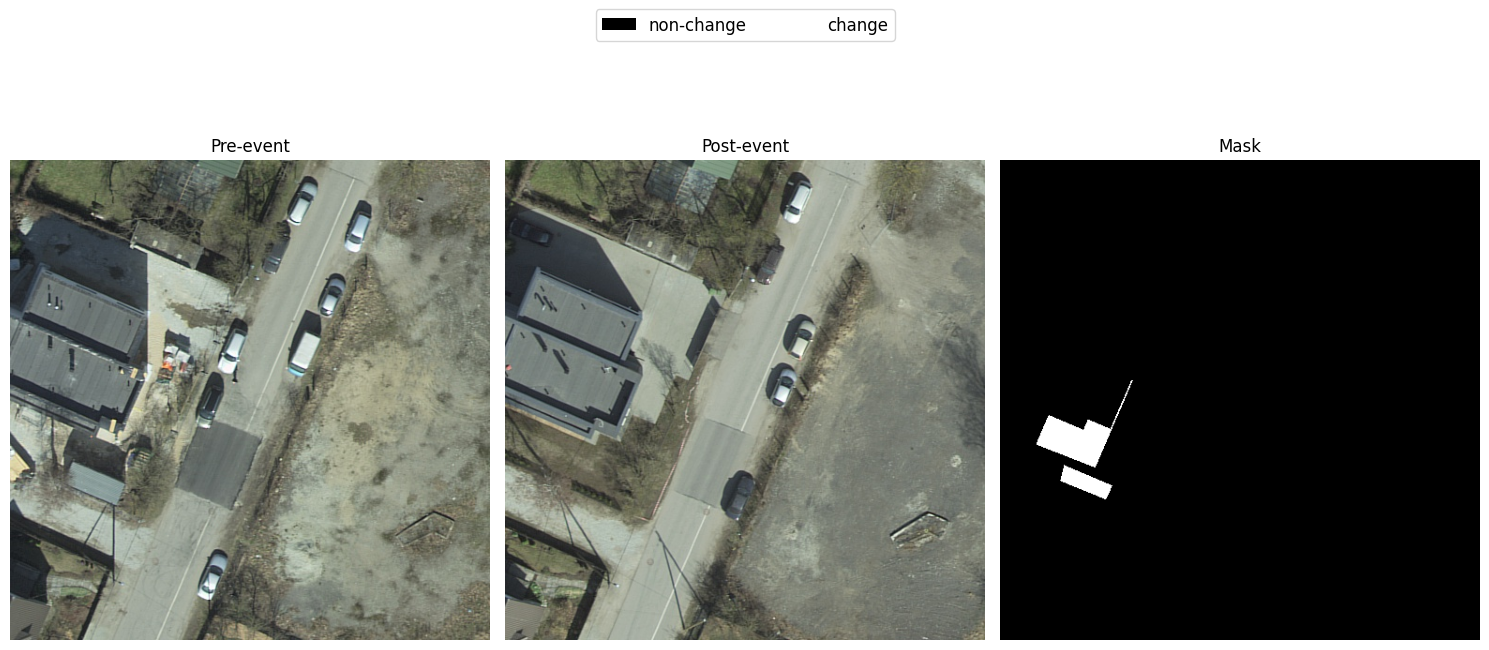

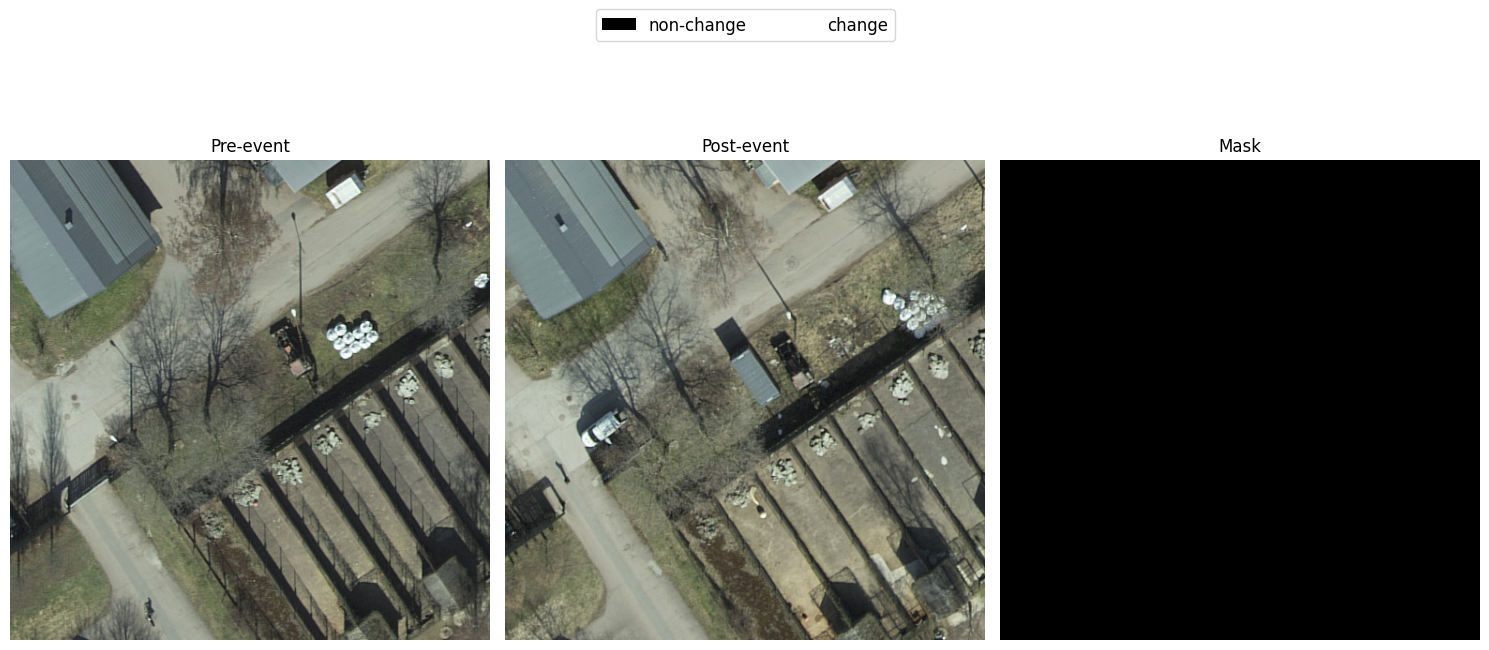

In [9]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/hi_ucd/train/",
    "task_type": "binary"
}
dataset = HiUCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(48);
dataset.show_image(29);
dataset.show_image(2000);

## Load training and test data

In [5]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/hi_ucd/train/",
    "task_type": "binary",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = HiUCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/hi_ucd/val/",
    "task_type": "binary",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = HiUCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(12000, 7200)

## Create the model

In [6]:
epochs = 2
model_directory = "/home/dragik/data/FAIR_EO/experiments/hi_ucd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [18]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-28 13:22:54,830 INFO Starting training.
training: 100%|██████████| 375/375 [3:46:49<00:00, 36.29s/it]  
2026-01-28 17:09:44,345 INFO epoch: 1, loss:  0.13261
testing on train set: 100%|██████████| 375/375 [3:40:01<00:00, 35.20s/it]  
2026-01-28 20:49:47,141 INFO Accuracy:0.9887486044565836, Accuracy per Class:[0.98834435 0.98915286], Precision Micro:0.9883706005345753, Precision Macro:0.49418530026728763, Precision Weighted:0.977641216789113, Precision per Class:[0.9883706 0.       ], Recall Micro:0.9891177829234499, Recall Macro:0.4999865596492947, Recall Weighted:0.9891177829234499, Recall per Class:[0.99997312 0.        ], F1_score Micro:0.9887440505697702, F1_score Macro:0.4970690040062628, F1_score Weighted:0.9833460154359084, F1_score per Class:[0.99413801 0.        ], IOU:0.9777386735048208, IOU mean:0.49417217070118014, IOU per Class:[0.98834434 0.        ]
training: 100%|██████████| 375/375 [3:26:18<00:00, 33.01s/it]  
2026-01-29 00:16:05,824 INFO epoch: 2, loss:  0.03

## Predictions

2026-01-29 07:43:13,251 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/hi_ucd/checkpoint.pth.tar
2026-01-29 07:43:13,684 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/hi_ucd/checkpoint.pth.tar at epoch 3


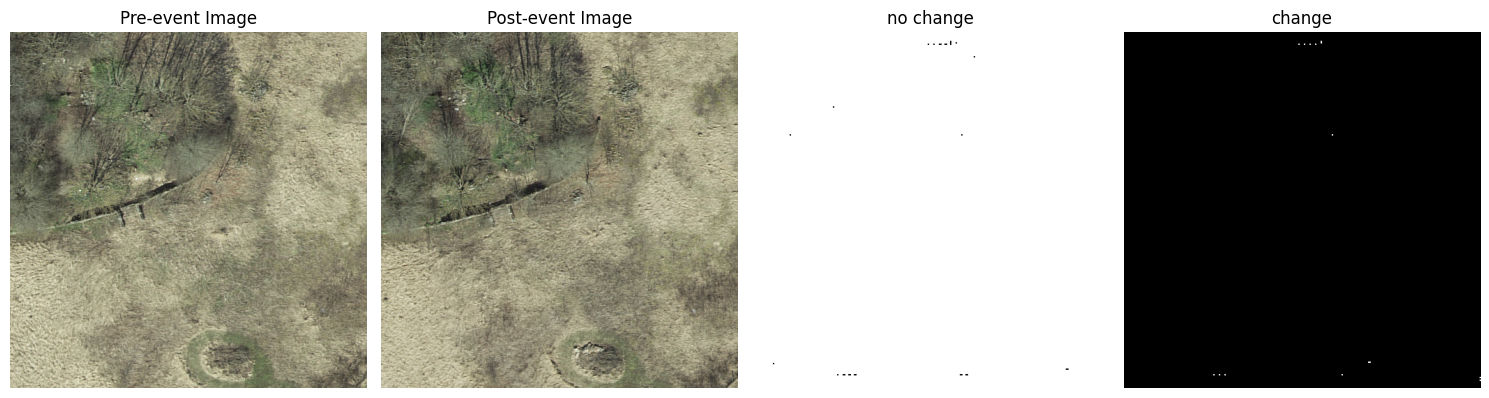

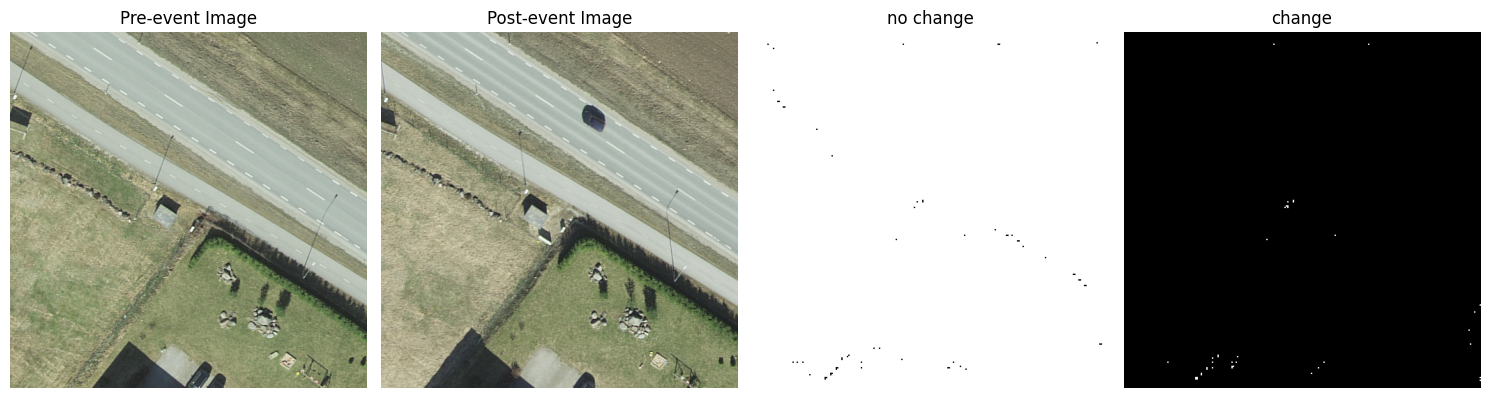

In [7]:
model_path = "/home/dragik/data/FAIR_EO/experiments/hi_ucd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("/home/dragik/data/FAIR_EO/hi_ucd/test/image/2018/5.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/hi_ucd/test/image/2019/5.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("/home/dragik/data/FAIR_EO/hi_ucd/test/image/2018/67.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/hi_ucd/test/image/2019/67.png")
fig = model.predict_masks(image1, image2, labels, transform)